In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_results.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

495 rows  |  63 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error
0,801,2948954099,Medical image analysis using supervised deep l...,ERROR: prompt too long (4185 tokens > 3830 limit),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,True
1,1182,2979645311,We revisit the challenge of designing online a...,We propose a hybrid algorithm for convex semid...,0.2587,0.0201,0.1592,0.8633,0.7974,0.8291,2.0,8.0,8.0,11,False
2,1203,2983100209,"In this work, we contribute a large-scale stud...",This paper presents a novel approach to imitat...,0.2609,0.0073,0.1232,0.8325,0.8402,0.8363,2.0,6.0,5.0,10,False


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

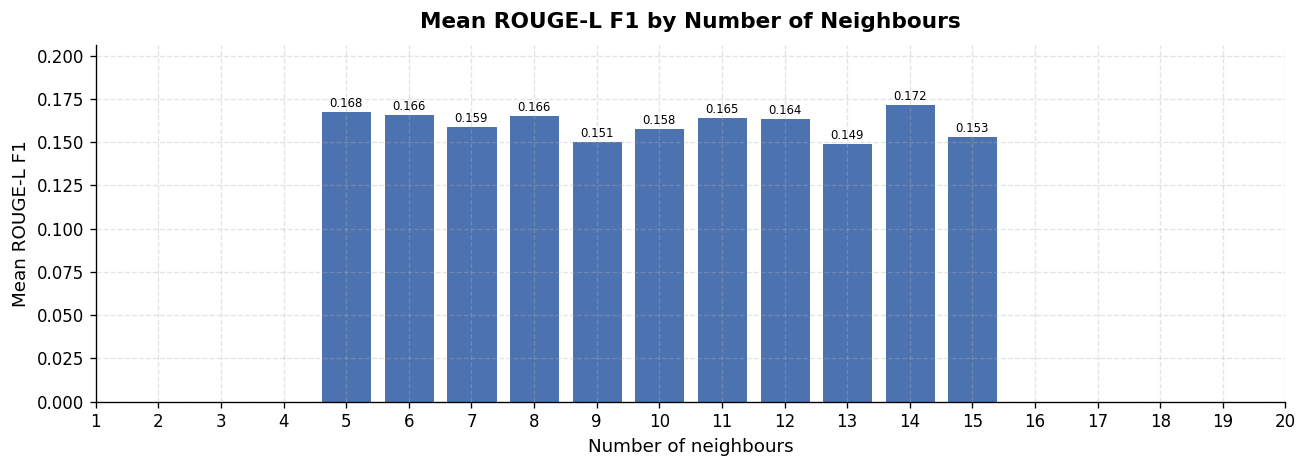

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

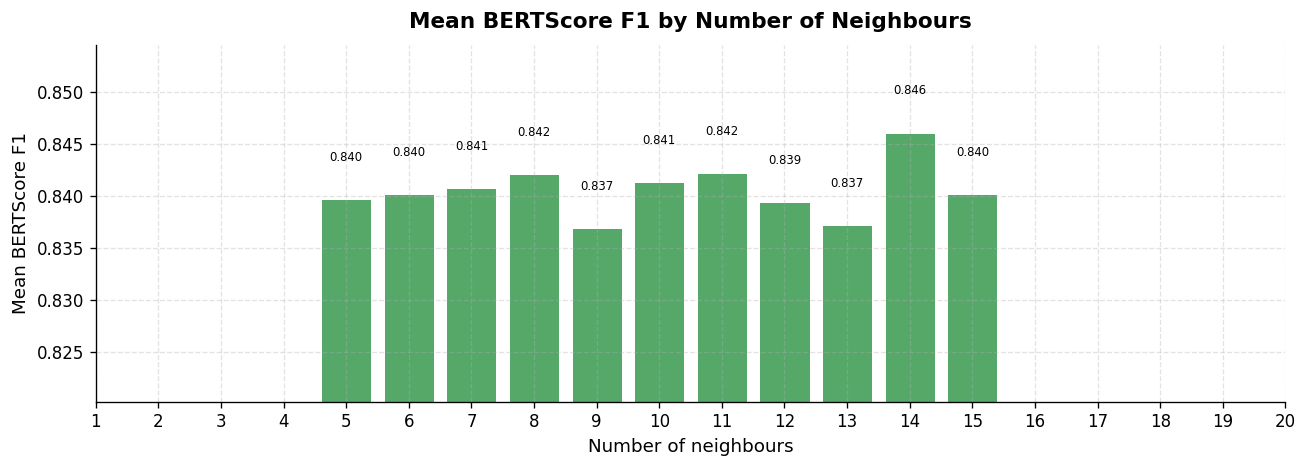

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

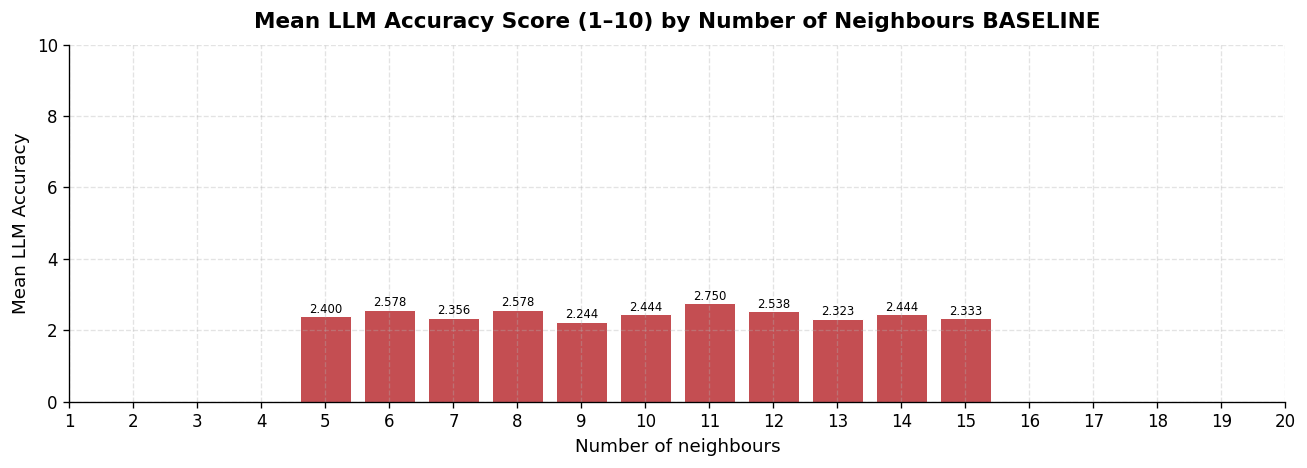

In [9]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours BASELINE',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

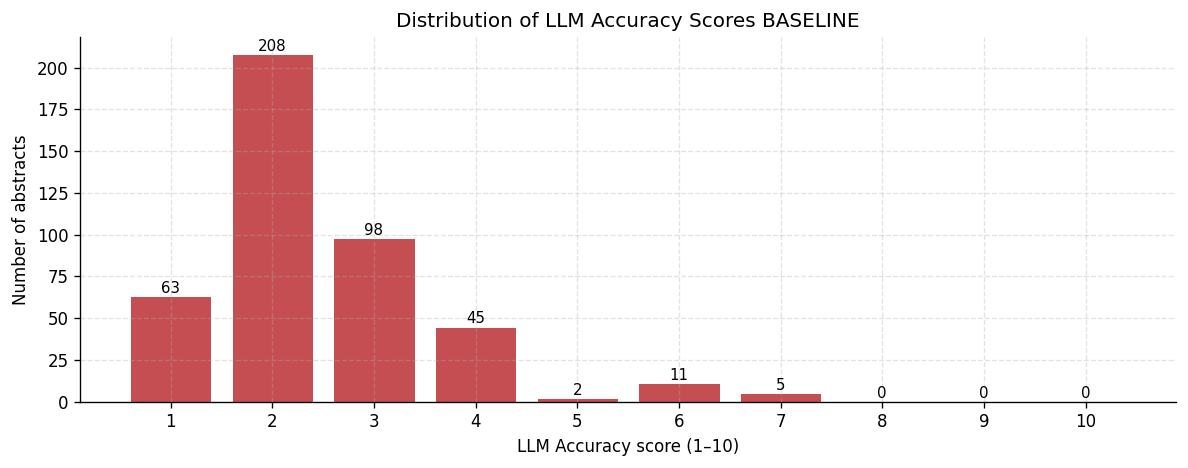

llm_accuracy
1      63
2     208
3      98
4      45
5       2
6      11
7       5
8       0
9       0
10      0
Name: count, dtype: int64

In [8]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores BASELINE')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

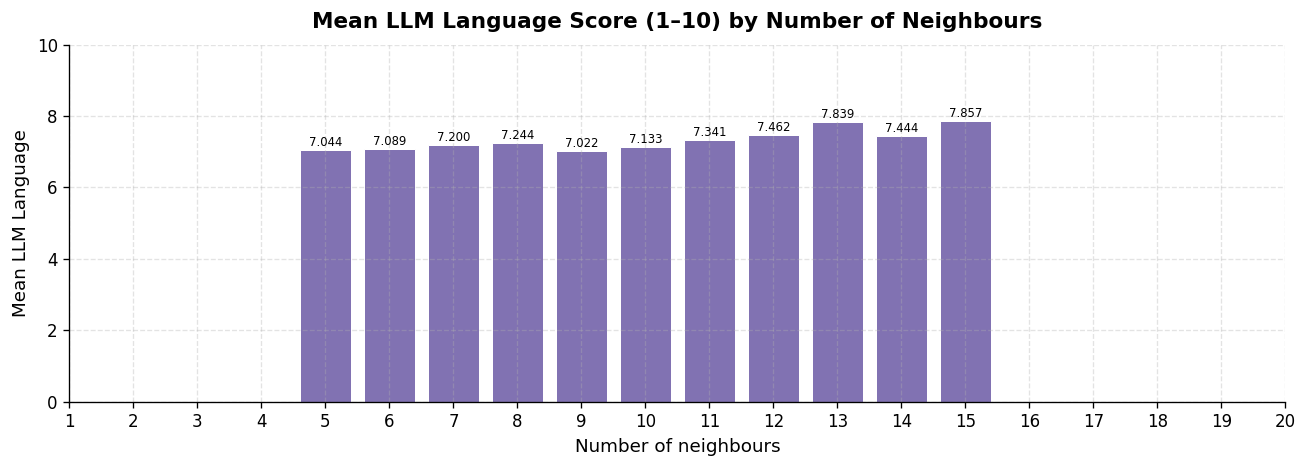

In [6]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

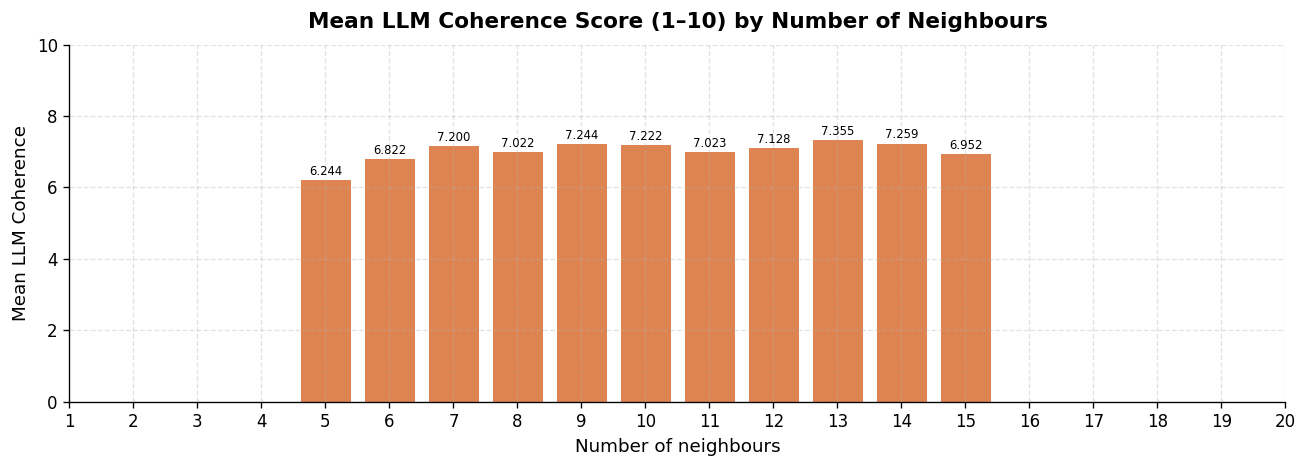

In [12]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

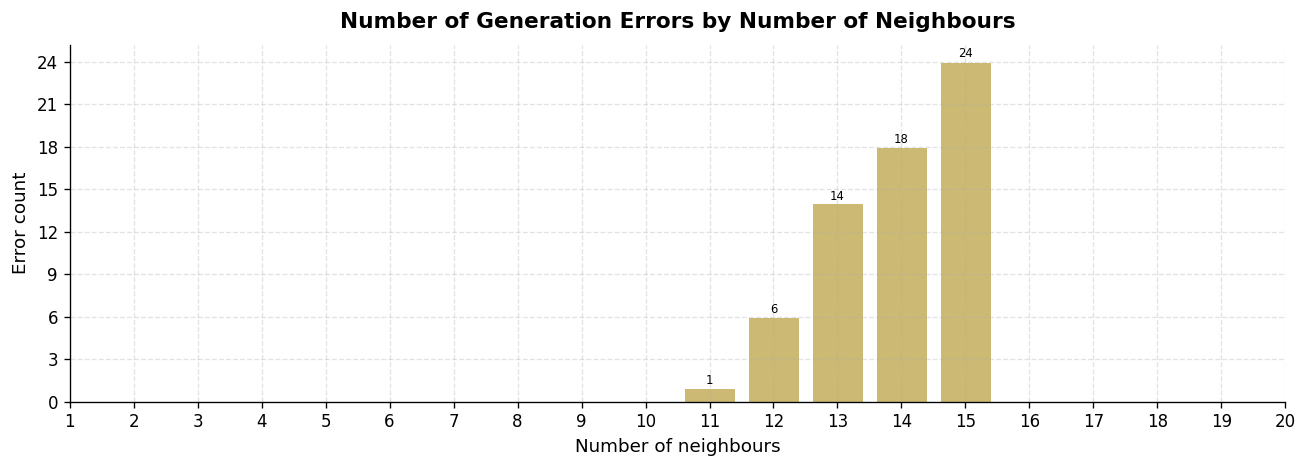

In [13]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [14]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_12920/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,25129,"Safety Case has become an integral component for safety-certification in various Cyber Physical System domains including automotive, aviation, medical devices, and military. The certification processes for these systems are stringent and require robust safety assurance arguments and substantial evidence backing. Despite the strict requirements, current practices still rely on manual methods that are brittle, do not have a systematic approach or thorough consideration of sound arguments. In addition, stringent certification requirements and ever-increasing system complexity make ad-hoc, manual assurance case generation (ACG) inefficient, time consuming, and expensive. To improve the current state of practice, we introduce a structured ACG tool which uses system design artifacts, accumulated evidence, and developer expertise to construct a safety case and evaluate it in an automated manner. We also illustrate the applicability of the ACG tool on a remote-control car testbed case study.","In this paper, we propose a framework for the design of a system that can be used to perform a mission. The framework is based on the use of a Mission-Based Reliability Block Diagram (MBRBD) that is used to model the system and its components. The MBRBD is a graphical representation of the system that shows the relationships between the components and the functions that they perform. The framework is based on the use of a Mission-Based Reliability Block Diagram (MBRBD) that is used to model the system and its components. The MBRBD is a graphical representation of the system that shows the relationships between the components and the functions that they perform. The framework is based on the use of a Mission-Based Reliability Block Diagram (MBRBD) that is used to model the system and its components. The MBRBD is a graphical representation of the system that shows the relationships between the components and the functions that they perform. The framework is based on the use of a Mission-Based Reliability Block Diagram (MBRBD) that is used to model the system and its components. The MBRBD is a graphical representation of the system that shows the",1.0
1,81487,"We empirically study the interplay between exploration and competition. Systems that learn from interactions with users often engage in exploration: making potentially suboptimal decisions in order to acquire new information for future decisions. However, when multiple systems are competing for the same market of users, exploration may hurt a system's reputation in the near term, with adverse competitive effects. In particular, a system may enter a ""death spiral"", when the short-term reputation cost decreases the number of users for the system to learn from, which degrades its performance relative to competition and further decreases its market share. #R##N#We ask whether better exploration algorithms are incentivized under competition. We run extensive numerical experiments in a stylized duopoly model in which two firms deploy multi-armed bandit algorithms and compete for myopic users. We find that duopoly and monopoly tend to favor a primitive ""greedy algorithm"" that does not explore and leads to low consumer welfare, whereas a temporary monopoly (a duopoly with an early entrant) may incentivize better bandit algorithms and lead to higher consumer welfare. Our findings shed light on the first-mover advantage in the digital economy by exploring the role that data can play as a barrier to entry in online markets.","We consider a multi-armed bandit problem where the bandit is a multi-armed bandit with a single arm, and the arms are the possible values of the bandit's private information. The bandit's goal is to learn the distribution of the private information, and the bandit's performance is measured by the regret. We show that the regret of the bandit is bounded by a constant factor of the number of arms, and is equal to

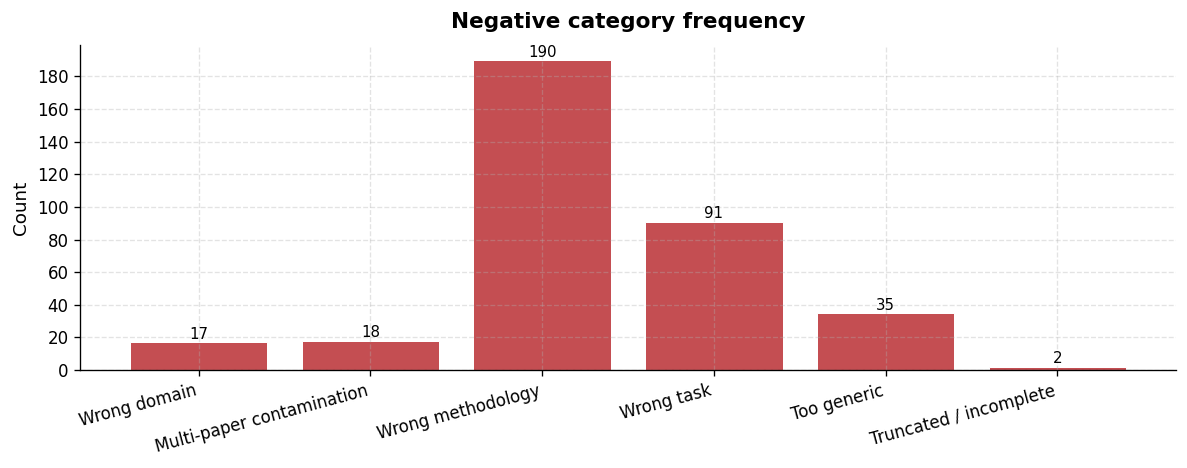

In [12]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


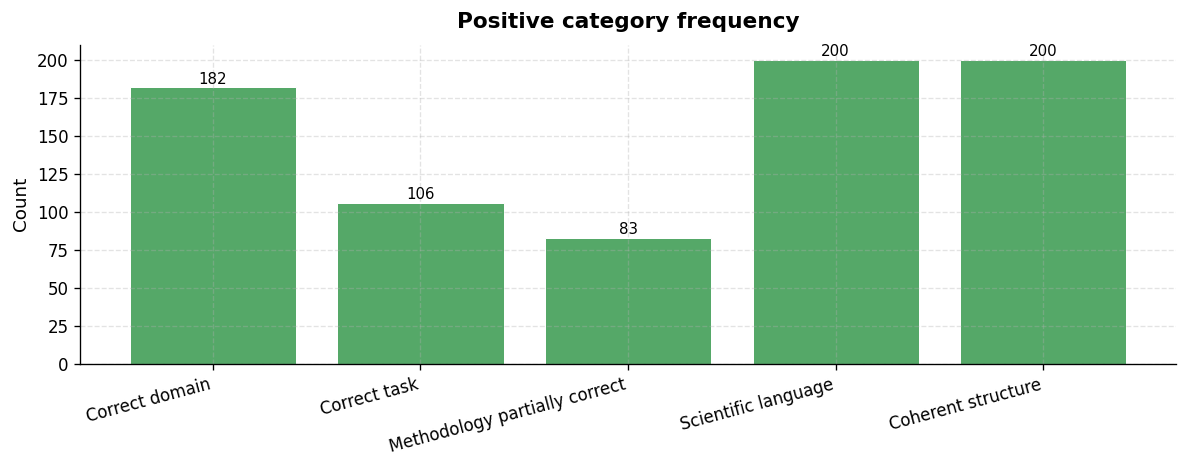

In [13]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()